In this activity we will implement the **fib** function to generate a spiral representing the first *n* fibonacci numbers, like in the following graphic.

![fibonacci](/modules/fibonacci/fibonacci.svg)

The fibonacci spiral is composed by **square** tiles with a **circular sector** going from corner to corner, rotated and increasing in size. The first thing we will have to do is to implement the **tile** function that just returns a square of the given color and size, with a black circular sector of 90 degrees (whose radius is equal to the square's side) on top of it, and a smaller circular sector of the square's color covering part of the black one, to make the illusion of a black line. The difference between the black circular sector and the covering circular sector should be the given ***line_thickness***

To achieve the wanted effect you will need to use <API>pin</API> and <API>compose</API> to pin everything in the bottom left corner.

In [ ]:
from pytamaro import Graphic, Color, rectangle, circular_sector, black, pin, compose, bottom_left, show_graphic, white


def tile(size: float, color: Color, line_thickness: float) -> Graphic:
    return # TODO


show_graphic(tile(150, white, 5))

In [ ]:
#teacher-only
from pytamaro import Graphic, Color, rectangle, circular_sector, black, pin, compose, bottom_left, show_graphic, white


def tile(size: float, color: Color, line_thickness: float) -> Graphic:
    rec = rectangle(size, size, color)
    outer_circle = circular_sector(size, 90, black)
    inner_circle = circular_sector(size - line_thickness, 90, color)
    return compose(
        pin(bottom_left, inner_circle),
        compose(
            pin(bottom_left, outer_circle),
            pin(bottom_left, rec)
        )
    )


show_graphic(tile(150, white, 5))

Each tile should be rotated by 90 degrees with respect to the previous one. This means that the first tile should stay the same, the second tile should be rotated by 90 degrees, the third should be rotated by 180 degrees and the fourth by 270 degrees, then the fifth should stay the same and so on.

Let's implement an **orient** function that returns the given tile rotated according to the given ***n***. If ***n*** == 0 the tile should not be rotated and so on (same rules as before but the first tile is for n=0, second tile is for n=1 etc.).

In [ ]:
from pytamaro import Graphic, rotate, show_graphic

def orient(tile: Graphic, n: int) -> Graphic:
    return # TODO


show_graphic(orient(tile(150, white, 5)), 0)  # change the n from 0 to test your implementation

In [ ]:
#teacher-only
from pytamaro import  Graphic, rotate, show_graphic

def orient(tile: Graphic, n: int) -> Graphic:
    return rotate((n % 4) * 90, tile)

show_graphic(orient(tile(150, white, 5), 0)) # change the n from 0 to test your implementation

Now we are ready to implement the **fib** function. This function takes the number of tiles of your final spiral as the parameter ***n***. The spiral becomes very large very quickly, so feel free to adapt the given `MIN_SIZE` constant when you put a bigger ***n***.

The `MIN_SIZE` is the size that the smallest two tiles should have (the first two tiles should have the same size, since fibonacci's sequence goes 1, 1, 2, 3, 5, ...). 

Depending on how you implemented the **orient** function, the first two tiles should be placed one <API>above</API> the other or one <API>beside</API> the other, so that the black lines align. 

Then, the third tile should be ***as wide*** or ***as tall*** as the first two tiles together (always in order for the black lines to align) and so on.

The given `THICKNESS` should also be adapted according to the wanted ***n***, since the final result can become very large.

There are multiple ways to achieve the wanted result but we will guide you through the implementation of the **fib** function as a *recursive function*.

A recursive function should have a ***base case*** and a ***recursive step***.

- the ***base case*** should return the first tile
- the ***recursive step*** should generate a new tile oriented according to the given **n**, and combine it with the result of a **call** to the **fib** function with ***n - 1***.

This way, the base case **fib(0)** will be executed first, then **fib(1)** will generate a new tile and combine it with the first one, then **fib(2)** will generate a new tile and combine it with the result of **fib(1)**, until **f(n)** returns the final result.

In [ ]:
from pytamaro import Graphic, Color, graphic_width, graphic_height, above, beside, white, show_graphic


MIN_SIZE = 40
THICKNESS = 10


def fib(n: int, color: Color) -> Graphic:
    if n < 1 :  # base case
        return tile(MIN_SIZE, color, THICKNESS)
    else:       # recursive step
        prev_tiles = fib(n - 1, color)
        # the new tile's size should be either the width or the height of the prev_tiles, depending on n % 2
        new_tile = # TODO

        # combine the two graphics with beside or above in the correct order.
        if n % 4 == 0:
            return # TODO
        elif n % 4 == 1:
            return # TODO
        elif n % 4 == 2:
            return # TODO
        else:
            return # TODO



show_graphic(fib(5, white))

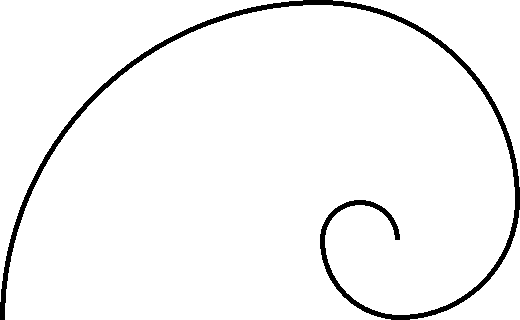

In [5]:
#teacher-only
from pytamaro import Graphic, Color, graphic_width, graphic_height, above, beside, white, show_graphic

MIN_SIZE = 40
THICKNESS = 5


def fib(n: int, color: Color) -> Graphic:
    if n < 1:  # base case
        return tile(MIN_SIZE, color, THICKNESS)
    else:      # recursive step
        prev_piece = fib(n - 1, color)
        size = graphic_height(prev_piece) if n % 2 != 0 else graphic_width(prev_piece)
        new_piece = orient(tile(size, color, THICKNESS), n)
        if n % 4 == 0:
            return above(new_piece, prev_piece)
        elif n % 4 == 1:
            return beside(new_piece, prev_piece)
        elif n % 4 == 2:
            return above(prev_piece, new_piece)
        else:
            return beside(prev_piece, new_piece)


show_graphic(fib(5, white))